In [ ]:
!pip install -q mediapipe opencv-python-headless

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from google.colab import files

print("MediaPipe And OpenCV Loaded Successfully")
print(f"OpenCV Version: {cv2.__version__}")
print(f"MediaPipe Version: {mp.__version__}")

MediaPipe And OpenCV Loaded Successfully
OpenCV Version: 5.0.0
MediaPipe Version: 1.2.3


In [ ]:
model_path = 'face_landmarker.task'

if not os.path.exists(model_path):
  print("Downloading Face Landmarker Model...")
  url = 'https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task'
  !wget -q {url} -O {model_path}
  print("Model Downloaded Successfully")
else:
  print("Model Already Exists.")

Model Already Exists.


In [ ]:
os.makedirs('images', exist_ok=True)

uploaded1 = files.upload()
src_path = None
for f in uploaded1.keys():
  src_path = os.path.join('images', f)
  os.rename(f, src_path)
  print(f"Source Image Saved: {src_path}")

uploaded2 = files.upload()
dst_path = None
for f in uploaded2.keys():
  dst_path = os.path.join('images', f)
  os.rename(f, dst_path)
  print(f"Destination Image Saved: {dst_path}")

Saving Donald-Trump.jpg to Donald-Trump.jpg
Source Image Saved: images/Donald-Trump.jpg


Saving Hillary-Clinton.jpg to Hillary-Clinton.jpg
Destination Image Saved: images/Hillary-Clinton.jpg


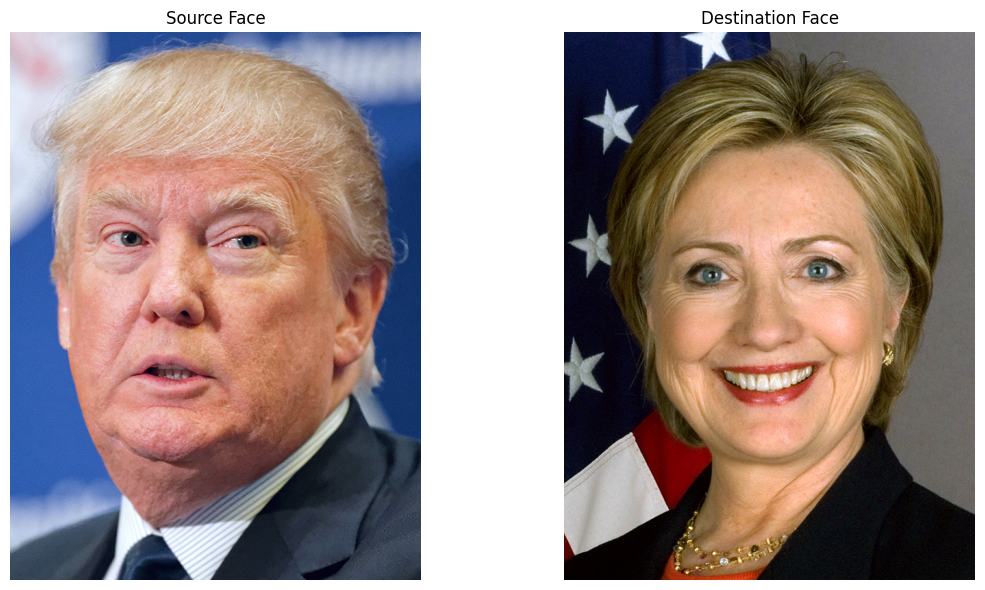

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

if src_path:
  img = cv2.imread(src_path)
  axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
  axes[0].set_title("Source Face")
  axes[0].axis('off')

if dst_path:
  img = cv2.imread(dst_path)
  axes[1].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
  axes[1].set_title("Destination Face")
  axes[1].axis('off')

plt.tight_layout()
plt.show()

In [31]:
src_img = cv2.imread(src_path)
dst_img = cv2.imread(dst_path)

src_points = get_face_landmarks(src_path)
dst_points = get_face_landmarks(dst_path)

print(f"Source Landmarks: {len(src_points)}")
print(f"Destination Landmarks: {len(dst_points)}")

Source Landmarks: 478
Destination Landmarks: 478


In [32]:
def get_convex_hull_indices(points):
    pts = np.array(points, dtype=np.float32)

    if len(pts) < 3:
        return list(range(len(pts)))

    hull = cv2.convexHull(pts)
    idx = []

    for hp in hull[:, 0, :]:
        d = np.sum((pts - hp) ** 2, axis=1)
        idx.append(int(np.argmin(d)))
    return idx

def get_delaunay_triangles(points, image_shape, tol=2.5):
    h, w = image_shape[:2]
    clean = []

    for (x, y) in points:
        x = float(np.clip(x, 0, w - 1))
        y = float(np.clip(y, 0, h - 1))
        key = (round(x, 2), round(y, 2))

        if key not in clean:
            clean.append(key)

    if len(clean) < 3:
        return []

    rect = (0.0, 0.0, float(w), float(h))
    subdiv = cv2.Subdiv2D(rect)

    for (x, y) in clean:
        subdiv.insert((x, y))

    pts_arr = np.array(clean, dtype=np.float32)
    delaunay = []

    for t in subdiv.getTriangleList():
        corners = [(float(t[0]), float(t[1])),
                   (float(t[2]), float(t[3])),
                   (float(t[4]), float(t[5]))]

        if any(c[0] < -1 or c[0] > w + 1 or c[1] < -1 or c[1] > h + 1 for c in corners):
            continue

        idx, ok = [], True

        for cx, cy in corners:
            d = np.sum((pts_arr - np.array([cx, cy])) ** 2, axis=1)
            j = int(np.argmin(d))
            if d[j] > tol ** 2:
                ok = False
                break
            idx.append(j)

        if ok and len(set(idx)) == 3:
            delaunay.append(tuple(idx))
    return delaunay


def warp_triangle(src_img, dst_img, t_src, t_dst):
    r1 = cv2.boundingRect(np.float32([t_src]))
    r2 = cv2.boundingRect(np.float32([t_dst]))
    rw, rh = r2[2], r2[3]
    if rw < 1 or rh < 1:
        return dst_img

    t1_rect = [(t_src[i][0] - r1[0], t_src[i][1] - r1[1]) for i in range(3)]
    t2_rect = [(t_dst[i][0] - r2[0], t_dst[i][1] - r2[1]) for i in range(3)]
    t2_int = np.int32([[int(round(p[0])), int(round(p[1]))] for p in t2_rect])

    crop = src_img[r1[1]:r1[1] + r1[3], r1[0]:r1[0] + r1[2]]
    if crop.size == 0:
        return dst_img

    mask = np.zeros((rh, rw), dtype=np.float32)
    cv2.fillConvexPoly(mask, t2_int, (1.0,), 16, 0)

    M = cv2.getAffineTransform(np.float32(t1_rect), np.float32(t2_rect))
    warped = cv2.warpAffine(crop, M, (rw, rh), None,
                            flags=cv2.INTER_LINEAR,
                            borderMode=cv2.BORDER_REFLECT_101)

    roi = dst_img[r2[1]:r2[1] + rh, r2[0]:r2[0] + rw]

    if roi.shape[:2] != (rh, rw):
        return dst_img

    for c in range(3):
        roi[:, :, c] = roi[:, :, c] * (1.0 - mask) + warped[:, :, c] * mask
    return dst_img

def fill_convex_hull(src_pts, dst_pts, src_img, dst_img):
    s_hull_idx = get_convex_hull_indices(src_pts)
    d_hull_idx = get_convex_hull_indices(dst_pts)
    s_poly = np.int32([[src_pts[i]] for i in s_hull_idx]).reshape(-1, 2)
    d_poly = np.int32([[dst_pts[i]] for i in d_hull_idx]).reshape(-1, 2)
    r = cv2.boundingRect(d_poly)
    if r[2] < 2 or r[3] < 2:
        return dst_img

    crop = src_img[r[1]:r[1] + r[3], r[0]:r[0] + r[2]] if (
        src_img[r[1]:r[1]+r[3], r[0]:r[0]+r[2]].size > 0) else None

    mask = np.zeros((r[3], r[2]), np.float32)
    cv2.fillConvexPoly(mask, np.int32(d_poly - d_poly.min(0)), 1.0, 8)
    return dst_img

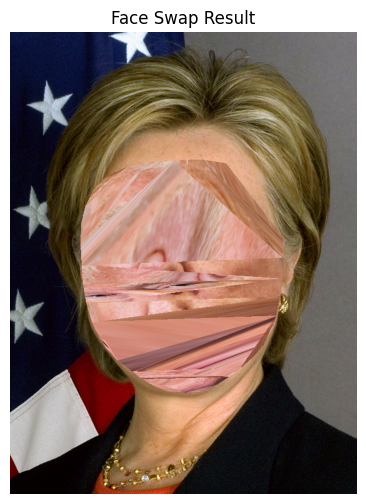

In [33]:
def swap_one_frame(frame, src_pts, dst_ref_pts):
    out = frame.copy()
    return out

src_img = cv2.imread(src_path)
dst_img = cv2.imread(dst_path)

_src_pts = [src_points]
_dst_pts = [dst_points]

if _src_pts and _dst_pts:
    swapped = dst_img.copy()
    s_i = get_convex_hull_indices(_src_pts[0])
    d_i = get_convex_hull_indices(_dst_pts[0])
    s_pts = [_src_pts[0][k] for k in s_i]
    d_pts = [_dst_pts[0][k] for k in d_i]
    tri_s = get_delaunay_triangles(s_pts, src_img.shape)
    tri_d = get_delaunay_triangles(d_pts, dst_img.shape)

    for i in range(min(len(tri_s), len(tri_d))):
        t_s = tuple(s_pts[v] for v in tri_s[i])
        t_d = tuple(d_pts[v] for v in tri_d[i])
        swapped = warp_triangle(src_img, swapped, t_s, t_d)

    plt.figure(figsize=(10, 6))

    plt.imshow(cv2.cvtColor(swapped, cv2.COLOR_BGR2RGB))
    plt.title("Face Swap Result")
    plt.axis("off")

    plt.show()

Applying Seamless Cloning...


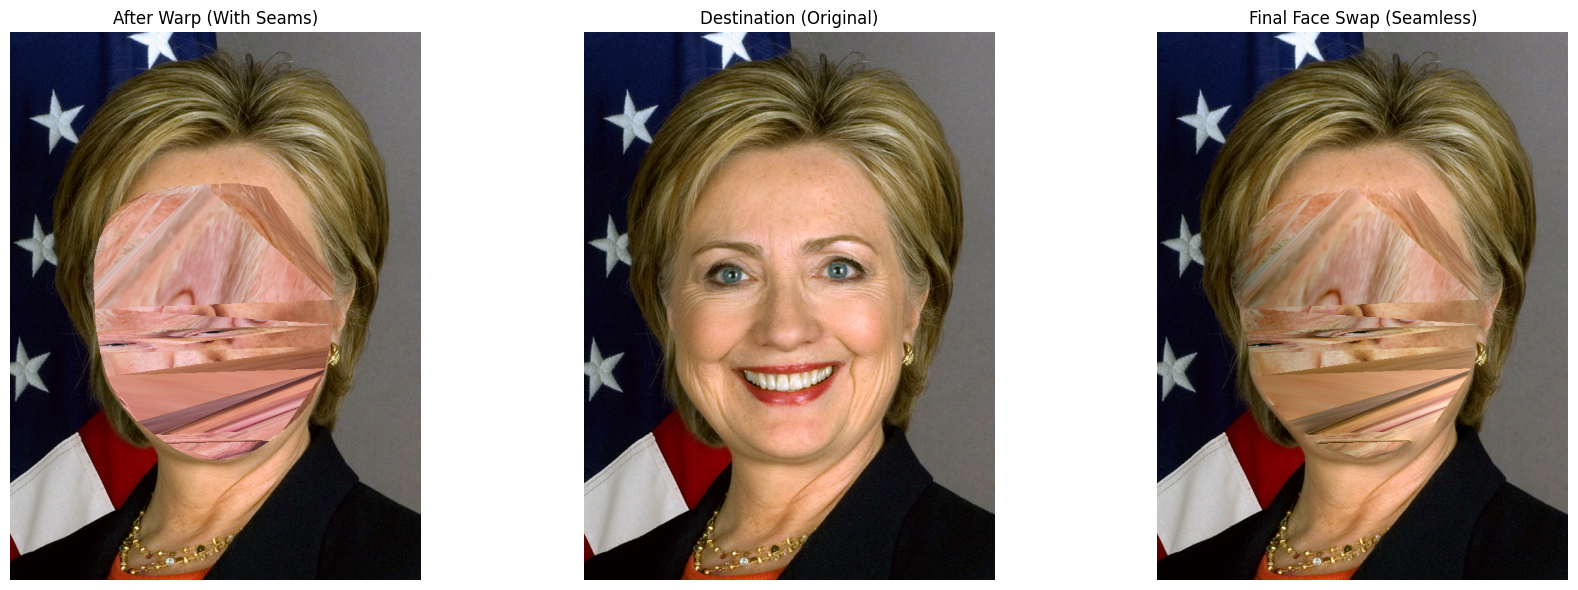

Saved: face_swap_result.jpg


In [34]:
d_hull_idx = get_convex_hull_indices(dst_points)
d_hull_pts = np.array([dst_points[i] for i in d_hull_idx], dtype=np.int32)

mask = np.zeros(dst_img.shape[:2], dtype=np.uint8)
cv2.fillConvexPoly(mask, d_hull_pts, 255)

x, y, w, h = cv2.boundingRect(d_hull_pts)
center = (x + w // 2, y + h // 2)

print("Applying Seamless Cloning...")
output = cv2.seamlessClone(swapped, dst_img, mask, center, cv2.NORMAL_CLONE)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(cv2.cvtColor(swapped, cv2.COLOR_BGR2RGB))
axes[0].set_title("After Warp (With Seams)")
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(dst_img, cv2.COLOR_BGR2RGB))
axes[1].set_title("Destination (Original)")
axes[1].axis('off')

axes[2].imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
axes[2].set_title("Final Face Swap (Seamless)")
axes[2].axis('off')

plt.tight_layout()
plt.show()

cv2.imwrite('face_swap_result.jpg', output)
print("Saved: face_swap_result.jpg")

In [ ]:
if os.path.exists('face_swap_result.jpg'):
  files.download('face_swap_result.jpg')
  print("Final Result Downloaded.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Final Result Downloaded.
